## **Genome Identification**

**Ответ**: E. coli K-12 MG1655 (NC_000913.3)

In [2]:
import sys
import Bio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO

print("Python:", sys.version.split()[0])
print("Biopython:", Bio.__version__)
print("Окружение:", sys.executable)

Python: 3.11.17
Biopython: 1.88
Окружение: /Users/danasokol/miniconda3/envs/genome-base/bin/python


In [3]:
#Путь до генома
project_dir = Path.cwd().parent
genome_path = project_dir / "data/raw/genome.fna"

print("Папка проекта:", project_dir)
print("Путь к геному:", genome_path)
print("Файл найден:", genome_path.exists())

Папка проекта: /Users/danasokol/Desktop/bioinformatics/projects/genome_annotation
Путь к геному: /Users/danasokol/Desktop/bioinformatics/projects/genome_annotation/data/raw/genome.fna
Файл найден: True


In [4]:
#Количество последовательностей и общая длина генома

sequences = list(SeqIO.parse(genome_path, "fasta"))

print("Количество последовательностей:", len(sequences))
print("Общая длина генома:", sum(len(s) for s in sequences), "п.н.")


Количество последовательностей: 1
Общая длина генома: 4641652 п.н.


In [5]:
record = sequences[0]

print("ID:", record.id)
print("Описание:", record.description)
print("Длина:", len(record.seq))

ID: 1
Описание: 1
Длина: 4641652


In [6]:
from collections import Counter

seq = str(record.seq).upper()
counts = Counter(seq)

for base in "ACGTN":
    print(f"{base}: {counts.get(base, 0):,}")

acgt = sum(counts.get(base, 0) for base in "ACGT")
gc = counts["G"] + counts["C"]

gc_percent = 100 * gc / acgt if acgt else float("nan")
n_percent = 100 * counts["N"] / len(seq)

print(f"\nGC-состав: {gc_percent:.2f}%")
print(f"Содержание N: {n_percent:.4f}%")
print("Другие символы:", {k: v for k, v in counts.items() if k not in "ACGTN"})

A: 1,142,742
C: 1,180,091
G: 1,177,437
T: 1,141,382
N: 0

GC-состав: 50.79%
Содержание N: 0.0000%
Другие символы: {}


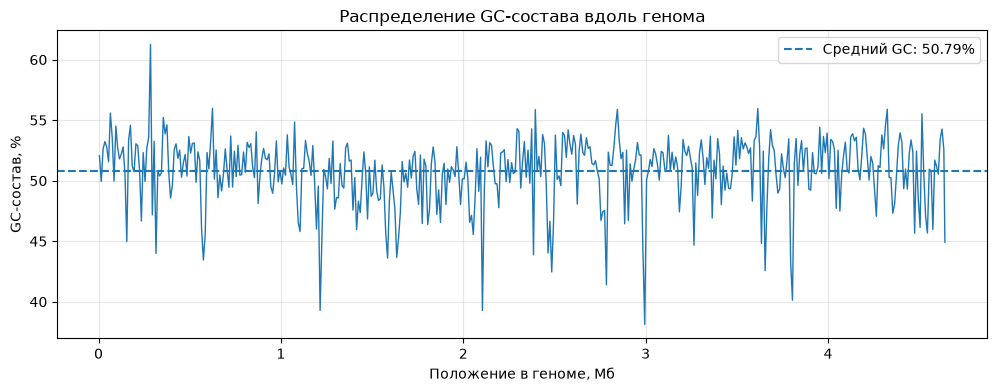

In [7]:
#Построим GC-профиль вдоль генома

window_size = 10_000
positions = []
gc_values = []

for start in range(0, len(seq), window_size):
    fragment = seq[start:start + window_size]

    gc = fragment.count("G") + fragment.count("C")
    acgt = sum(fragment.count(base) for base in "ACGT")

    positions.append((start + len(fragment) / 2) / 1e6)
    gc_values.append(100 * gc / acgt if acgt else np.nan)

plt.figure(figsize=(12, 4))

plt.plot(positions, gc_values, linewidth=1)
plt.axhline(gc_percent, linestyle="--",
            label=f"Средний GC: {gc_percent:.2f}%")

plt.xlabel("Положение в геноме, Мб")
plt.ylabel("GC-состав, %")
plt.title("Распределение GC-состава вдоль генома")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
# Подготовим 1000 нуклеотидов для BLAST
mid = len(record.seq) // 2

fragment = SeqRecord(
    record.seq[mid:mid + 1000],
    id="genome_middle_fragment",
    description=""
)

output = project_dir / "data/processed/blast_fragment.fasta"

SeqIO.write(fragment, output, "fasta")

print("Файл сохранён:", output)

Файл сохранён: /Users/danasokol/Desktop/bioinformatics/projects/genome_annotation/data/processed/blast_fragment.fasta


In [9]:
from Bio import Entrez, SeqIO

Entrez.email = "danhiksokol@gmail.com"  

with Entrez.efetch(
    db="nuccore",
    id="NC_000913.3",
    rettype="fasta",
    retmode="text"
) as handle:
    reference = SeqIO.read(handle, "fasta")

print(reference.description)
print("Длина референса:", len(reference.seq))

same = str(record.seq).upper() == str(reference.seq).upper()
print("Полное совпадение:", same)

NC_000913.3 Escherichia coli str. K-12 substr. MG1655, complete genome
Длина референса: 4641652
Полное совпадение: True


____
### **Референсная структурная и функциональная аннотация E.coli K12 MG1655** 



In [10]:
#Посмотрим на количество аннотированных элементов в референсе
with Entrez.efetch(
    db="nuccore",
    id="NC_000913.3",
    rettype="gbwithparts",
    retmode="text"
) as handle:
    annotated_genome = SeqIO.read(handle, "genbank")

print("Организм:", annotated_genome.annotations["organism"])
print("Количество аннотированных элементов:",len(annotated_genome.features))


Организм: Escherichia coli str. K-12 substr. MG1655
Количество аннотированных элементов: 9285


In [11]:
#Типы аннотированных элементов в референсе
feature_counts = Counter(feature.type for feature in annotated_genome.features)

for feature_type, count in feature_counts.most_common():
    print(f"{feature_type:20s} {count}")

gene                 4651
CDS                  4318
ncRNA                108
tRNA                 86
mobile_element       50
misc_feature         48
rRNA                 22
source               1
rep_origin           1


Получим таблицу с координатами кодирующих последовательностей и функциями соответствующих белков.

In [12]:
#Таблица генов
genes = []

for feature in annotated_genome.features:
    if feature.type != "CDS":
        continue
    genes.append({
        "gene": feature.qualifiers.get("gene", ["unknown"])[0],
        "locus_tag": feature.qualifiers.get("locus_tag", [""])[0],
        "start": int(feature.location.start) + 1,
        "end": int(feature.location.end),
        "strand": feature.location.strand,
        "product": feature.qualifiers.get("product", ["unknown"])[0]
    })

genes_df = pd.DataFrame(genes)

display(genes_df.head(10))

,gene,locus_tag,start,end,strand,product
0,thrL,b0001,190,255,1,thr operon leader peptide
1,thrA,b0002,337,2799,1,fused aspartate kinase/homoserine dehydrogenase 1
2,thrB,b0003,2801,3733,1,homoserine kinase
3,thrC,b0004,3734,5020,1,threonine synthase
4,yaaX,b0005,5234,5530,1,DUF2502 domain-containing protein YaaX
5,yaaA,b0006,5683,6459,-1,DNA binding and peroxide stress response prote...
6,yaaJ,b0007,6529,7959,-1,putative transporter YaaJ
7,talB,b0008,8238,9191,1,transaldolase B
8,mog,b0009,9306,9893,1,molybdopterin adenylyltransferase
9,satP,b0010,9928,10494,-1,acetate/succinate:H(+) symporter


In [13]:
#Сохранение полной референсной аннотации GenBank
ref_dir = project_dir / "data" / "processed"
ref_dir.mkdir(parents=True, exist_ok=True)

SeqIO.write(
    annotated_genome,
    ref_dir / "NC_000913.3.gbk",
    "genbank"
)

# Таблица CDS
genes_df.to_csv(
    ref_dir / "reference_CDS.tsv",
    sep="\t",
    index=False
)

In [14]:
# Псевдогены
pseudogenes = [
    f for f in annotated_genome.features
    if f.type == "gene"
    and ("pseudo" in f.qualifiers
         or "pseudogene" in f.qualifiers)
]

print("Псевдогенов:", len(pseudogenes))

for feature in pseudogenes[:10]:
    print(
        feature.qualifiers.get("gene", ["unknown"])[0],
        feature.location
    )

Псевдогенов: 145
yafU [238745:239084](-)
yafF [239189:239378](+)
lfhA [248357:250070](-)
lafU [250071:250827](+)
ykfJ [253466:253733](+)
prfH [253701:254202](+)
crl [257828:259006](+)
ykfN [263149:263212](-)
ykfL [266552:266774](-)
ykfK [266775:266967](-)


______
### **Prodigal**

In [15]:
# Проверка первичного нахождения CDS
prodigal_dir = project_dir /"results/structural/prodigal"

proteins = list(SeqIO.parse(prodigal_dir / "proteins.faa", "fasta"))

n_prodigal = len(proteins)
n_reference = 4318

print(f"Prodigal: {n_prodigal} CDS")
print(f"NCBI:     {n_reference} CDS")
print(f"Разница:  {n_prodigal - n_reference:+d} CDS")

Prodigal: 4318 CDS
NCBI:     4318 CDS
Разница:  +0 CDS


In [16]:
#Координаты
gff_path = prodigal_dir / "genes.gff"
result_coords = []
with open(gff_path) as f:
    for i, line in enumerate(f):
        if i == 10:
            break
        print(line.strip())

##gff-version  3
# Sequence Data: seqnum=1;seqlen=4641652;seqhdr="1"
# Model Data: version=Prodigal.v2.6.3;run_type=Single;model="Ab initio";gc_cont=50.79;transl_table=11;uses_sd=1
1	Prodigal_v2.6.3	CDS	337	2799	337.5	+	0	ID=1_1;partial=00;start_type=ATG;rbs_motif=GGAG/GAGG;rbs_spacer=5-10bp;gc_cont=0.531;conf=99.99;score=337.53;cscore=320.95;sscore=16.58;rscore=11.24;uscore=1.40;tscore=3.94;
1	Prodigal_v2.6.3	CDS	2801	3733	118.1	+	0	ID=1_2;partial=00;start_type=ATG;rbs_motif=AGGAG;rbs_spacer=5-10bp;gc_cont=0.563;conf=100.00;score=118.07;cscore=97.71;sscore=20.37;rscore=14.85;uscore=0.32;tscore=3.94;
1	Prodigal_v2.6.3	CDS	3734	5020	194.3	+	0	ID=1_3;partial=00;start_type=ATG;rbs_motif=GGA/GAG/AGG;rbs_spacer=5-10bp;gc_cont=0.528;conf=99.99;score=194.28;cscore=189.96;sscore=4.33;rscore=2.99;uscore=-3.88;tscore=3.94;
1	Prodigal_v2.6.3	CDS	5234	5530	8.2	+	0	ID=1_4;partial=00;start_type=GTG;rbs_motif=AGGAG;rbs_spacer=5-10bp;gc_cont=0.539;conf=86.80;score=8.19;cscore=0.54;sscore=7.65;rscore=1

In [17]:
columns = ["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"]

prodigal_df = pd.read_csv(
    gff_path,
    sep="\t",
    comment="#",
    header=None,
    names=columns
)
prodigal_df = prodigal_df[prodigal_df["type"] == "CDS"].copy()

prodigal_df["strand"] = prodigal_df["strand"].map({
    "+": 1,
    "-": -1
})

display(prodigal_df.head())

,seqid,source,type,start,end,score,strand,phase,attributes
0,1,Prodigal_v2.6.3,CDS,337,2799,337.5,1,0,ID=1_1;partial=00;start_type=ATG;rbs_motif=GGA...
1,1,Prodigal_v2.6.3,CDS,2801,3733,118.1,1,0,ID=1_2;partial=00;start_type=ATG;rbs_motif=AGG...
2,1,Prodigal_v2.6.3,CDS,3734,5020,194.3,1,0,ID=1_3;partial=00;start_type=ATG;rbs_motif=GGA...
3,1,Prodigal_v2.6.3,CDS,5234,5530,8.2,1,0,ID=1_4;partial=00;start_type=GTG;rbs_motif=AGG...
4,1,Prodigal_v2.6.3,CDS,5683,6459,117.7,-1,0,ID=1_5;partial=00;start_type=ATG;rbs_motif=AGG...


In [18]:
#Сравнение координатс референсом
reference_coords = set(
    zip(
        genes_df["start"],
        genes_df["end"],
        genes_df["strand"]
    )
)

prodigal_coords = set(
    zip(
        prodigal_df["start"],
        prodigal_df["end"],
        prodigal_df["strand"]
    )
)

exact_matches = reference_coords & prodigal_coords

print("CDS NCBI:", len(reference_coords))
print("CDS Prodigal:", len(prodigal_coords))
print("Полных совпадений:", len(exact_matches))

print(
    "Доля совпадений относительно NCBI:",
    f"{len(exact_matches) / len(reference_coords) * 100:.2f}%"
)

print("CDS NCBI без точного совпадения:",
      len(reference_coords - prodigal_coords))

print("CDS Prodigal без точного совпадения:",
      len(prodigal_coords - reference_coords))

genes_df["exact_match"] = [
    (start, end, strand) in prodigal_coords
    for start, end, strand in zip(
        genes_df["start"],
        genes_df["end"],
        genes_df["strand"]
    )
]

mismatches = genes_df[~genes_df["exact_match"]].copy()

print("Генов с несовпадающими координатами:", len(mismatches))

display(mismatches.head(20))

CDS NCBI: 4318
CDS Prodigal: 4318
Полных совпадений: 3889
Доля совпадений относительно NCBI: 90.06%
CDS NCBI без точного совпадения: 429
CDS Prodigal без точного совпадения: 429
Генов с несовпадающими координатами: 429


,gene,locus_tag,start,end,strand,product,exact_match
0,thrL,b0001,190,255,1,thr operon leader peptide,False
11,mbiA,b0012,10830,11315,1,uncharacterized protein MbiA,False
16,mokC,b0018,16751,16960,-1,regulatory protein MokC,False
19,nhaR,b0020,18715,19620,1,DNA-binding transcriptional activator NhaR,False
20,insB1,b0021,19811,20314,-1,IS1 family protein InsB,False
23,yaaY,b0024,21181,21399,1,DUF2575 domain-containing protein YaaY,False
47,folA,b0048,49823,50302,1,dihydrofolate reductase,False
75,leuL,b0075,83622,83708,-1,leu operon leader peptide,False
77,yabR,b4726,85467,85511,-1,protein YabR,False
97,secM,b0097,107705,108217,1,SecA translation regulator,False


Возможны три принципиально разные ситуации:

1. Prodigal нашёл тот же ген, но выбрал другой старт трансляции.

2. Prodigal действительно пропустил ген, предсказав вместо него другую CDS.

3. Референсная аннотация содержит короткие, нестандартные или экспериментально подтверждённые CDS, которые сложно обнаружить стандартным алгоритмом.

In [19]:
# Координаты границ

ref = genes_df.copy()
pred = prodigal_df.copy()

for df in [ref, pred]:
    df["stop_boundary"] = np.where(
        df["strand"] == 1,
        df["end"],
        df["start"]
    )

    df["start_boundary"] = np.where(
        df["strand"] == 1,
        df["start"],
        df["end"]
    )

In [20]:
stop_matches = ref.merge(
    pred,
    on=["strand", "stop_boundary"],
    suffixes=("_ncbi", "_prodigal")
)

stop_matches["same_start"] = (
    stop_matches["start_boundary_ncbi"]
    == stop_matches["start_boundary_prodigal"]
)

stop_matches["start_shift_nt"] = (
    stop_matches["start_boundary_prodigal"]
    - stop_matches["start_boundary_ncbi"]
)

print("Совпадений по стоп-границе:", len(stop_matches))

print(
    "Одинаковые старты:",
    stop_matches["same_start"].sum()
)

print(
    "Разные старты при одинаковом стопе:",
    (~stop_matches["same_start"]).sum()
)

Совпадений по стоп-границе: 4139
Одинаковые старты: 3889
Разные старты при одинаковом стопе: 250


In [21]:
different_starts = stop_matches[
    ~stop_matches["same_start"]
].copy()

display(
    different_starts[
        [
            "gene",
            "start_ncbi",
            "end_ncbi",
            "start_prodigal",
            "end_prodigal",
            "strand",
            "start_shift_nt"
        ]
    ].head(20)
)

,gene,start_ncbi,end_ncbi,start_prodigal,end_prodigal,strand,start_shift_nt
14,mokC,16751,16960,16751,16903,-1,-57
17,nhaR,18715,19620,18721,19620,1,6
18,insB1,19811,20314,19811,20188,-1,-126
44,folA,49823,50302,49712,50302,1,-111
92,secM,107705,108217,107630,108217,1,-75
105,aroP,120178,121551,120178,121548,-1,-3
115,yacC,136570,136917,136570,136878,-1,-39
136,pcnB,157729,159126,157729,159093,-1,-33
143,mrcB,164865,167264,164730,167264,1,-135
158,yaeI,184257,185069,184257,185000,-1,-69


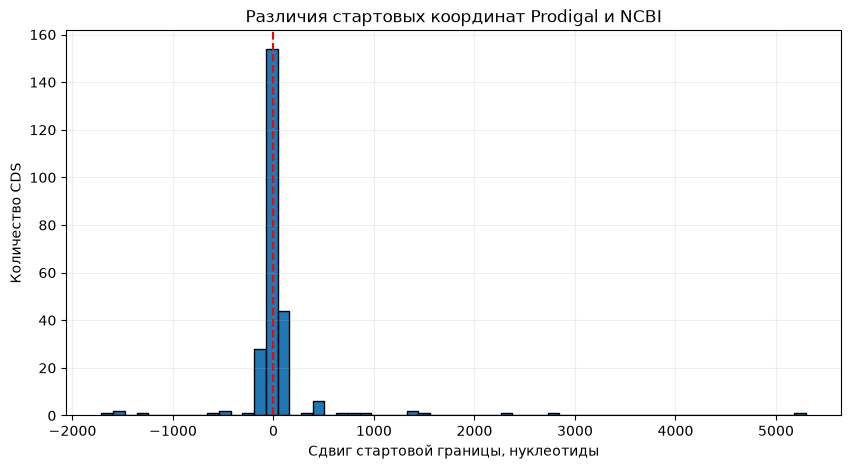

In [22]:
plt.figure(figsize=(10, 5))

plt.hist(
    different_starts["start_shift_nt"],
    bins=60,
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Сдвиг стартовой границы, нуклеотиды")
plt.ylabel("Количество CDS")
plt.title("Различия стартовых координат Prodigal и NCBI")
plt.grid(alpha=0.2)
plt.show()

In [ ]:
#Несовпадение по стоп границе
matched_stops = set(
    zip(
        stop_matches["strand"],
        stop_matches["stop_boundary"]
    )
)

unmatched_ref = ref[
    ~ref.apply(
        lambda row: (
            row["strand"],
            row["stop_boundary"]
        ) in matched_stops,
        axis=1
    )
].copy()

print("CDS без совпадения стоп-границы:", len(unmatched_ref))

display(unmatched_ref[["gene", "start", "end", "strand", "product"]].head(20))

CDS без совпадения стоп-границы: 179


,gene,start,end,strand,product
0,thrL,190,255,1,thr operon leader peptide
11,mbiA,10830,11315,1,uncharacterized protein MbiA
23,yaaY,21181,21399,1,DUF2575 domain-containing protein YaaY
75,leuL,83622,83708,-1,leu operon leader peptide
77,yabR,85467,85511,-1,protein YabR
103,yacM,113244,113288,1,protein YacM
155,yadX,175048,175095,1,protein YadX
157,yadW,176552,176617,1,protein YadW
209,ykfO,234288,234320,1,protein YkfO
249,insN,270278,272190,1,CP4-6 prophage; IS911A regulator fragment


        -> Проблема с короткими генами? 

Медиана всех CDS: 825.0
Медиана несовпавших CDS: 102.0
Доля CDS короче 300 п.н. среди всех: 12.1%
Доля CDS короче 300 п.н. среди несовпавших: 88.3%


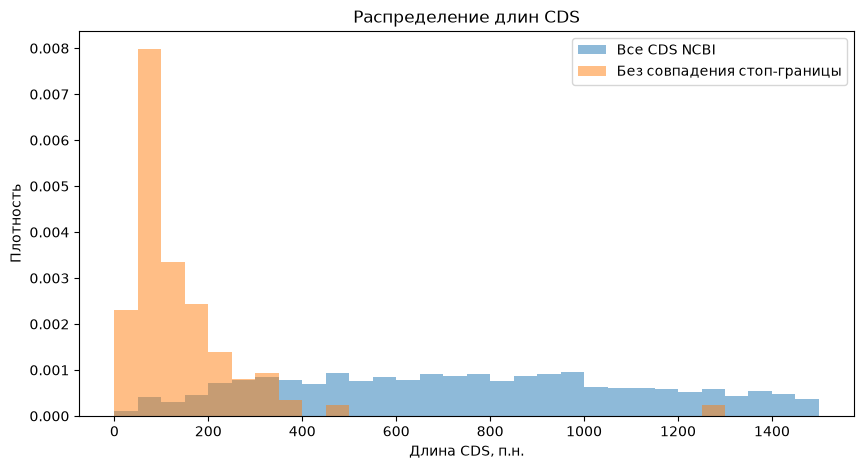

In [ ]:
#Посмотрим на распределение длин

import numpy as np
import matplotlib.pyplot as plt

# Длина CDS из NCBI
ref["length"] = ref["end"] - ref["start"] + 1

# Все CDS референса
all_lengths = ref["length"]

# CDS без совпадения стоп-границы
unmatched_ref["length"] = (unmatched_ref["end"] - unmatched_ref["start"] + 1)

unmatched_lengths = unmatched_ref["length"]

print("Медиана всех CDS:", all_lengths.median())
print("Медиана несовпавших CDS:", unmatched_lengths.median())

print(
    "Доля CDS короче 300 п.н. среди всех:",
    f"{(all_lengths < 300).mean() * 100:.1f}%"
)

print(
    "Доля CDS короче 300 п.н. среди несовпавших:",
    f"{(unmatched_lengths < 300).mean() * 100:.1f}%"
)

plt.figure(figsize=(10, 5))

bins = np.arange(0, 1501, 50)

plt.hist(
    all_lengths,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Все CDS NCBI"
)

plt.hist(
    unmatched_lengths,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Без совпадения стоп-границы"
)

plt.xlabel("Длина CDS, п.н.")
plt.ylabel("Плотность")
plt.title("Распределение длин CDS")
plt.legend()
plt.show()

In [25]:
ref["exact_match"] = [
    (start, end, strand) in prodigal_coords
    for start, end, strand in zip(
        ref["start"], ref["end"], ref["strand"]
    )
]

bins = [0, 150, 300, 600, 1000, 2000, np.inf]
labels = [
    "<150", "150–299", "300–599",
    "600–999", "1000–1999", "≥2000"
]

ref["length_group"] = pd.cut(
    ref["length"],
    bins=bins,
    labels=labels,
    right=False
)

quality_by_length = (
    ref.groupby("length_group", observed=True)
    .agg(
        total=("exact_match", "size"),
        matched=("exact_match", "sum"),
        accuracy=("exact_match", "mean")
    )
    .reset_index()
)

quality_by_length["accuracy"] *= 100

display(quality_by_length)

,length_group,total,matched,accuracy
0,<150,157,33,21.019108
1,150–299,364,309,84.890110
2,300–599,905,836,92.375691
3,600–999,1299,1231,94.765204
4,1000–1999,1324,1244,93.957704
5,≥2000,269,236,87.732342


Условимся на том, что короткие гены - являются проблемными участками.